# Assignment: a new ARIMA model on Nile flow

The supplied [Nile data](../data/nile.csv) contains 100 annual flows at Aswan,
1871–1970. It is fresh data relative to the energy exercise. The original
rubric suggests Duke datasets but does not require a particular source.
[Statsmodels documents the provenance and apparent break near 1898](https://www.statsmodels.org/stable/datasets/generated/nile.html).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

data = pd.read_csv('../data/nile.csv')
series = pd.Series(data.volume.to_numpy(), index=pd.date_range('1871',periods=len(data),freq='YS'),name='flow')
train, valid, test = series.iloc[:70], series.iloc[70:80], series.iloc[80:]
assert train.index.max() < valid.index.min() < test.index.min()
assert len(test) == 20 and series.gt(0).all()
print('Train:',train.index[0].year,train.index[-1].year,'Validation:',valid.index[0].year,valid.index[-1].year,
      'Test:',test.index[0].year,test.index[-1].year)
print('ADF p-values, training level and first difference:',adfuller(train)[1],adfuller(train.diff().dropna())[1])

Train: 1871 1940 Validation: 1941 1950 Test: 1951 1970
ADF p-values, training level and first difference: 0.020959912768547466 1.4783772554575567e-06


In [2]:
candidates = [(0,0,0),(1,0,0),(1,1,0),(1,0,1)]
rows = []
for order in candidates:
    result = SARIMAX(train,order=order,trend='c' if order[1]==0 else 'n',
                     enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=500)
    assert result.mle_retvals['converged']
    prediction = result.forecast(len(valid))
    rows.append({'order': order,'validation_MAPE_percent':100*mean_absolute_percentage_error(valid,prediction),'AIC':result.aic})
choice = min(rows,key=lambda row:row['validation_MAPE_percent'])
display(pd.DataFrame(rows))
print('Selected using validation only:',choice['order'])
history = pd.concat([train,valid])
fitted = SARIMAX(history,order=choice['order'],trend='c' if choice['order'][1]==0 else 'n',
                 enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=500)
assert fitted.mle_retvals['converged']
forecast = fitted.get_forecast(len(test))
prediction = forecast.predicted_mean
interval = forecast.conf_int(alpha=0.05)
predictions = {'ARIMA':prediction,'Last value':np.repeat(history.iloc[-1],len(test)),
               'Recent 20-year mean':np.repeat(history.iloc[-20:].mean(),len(test))}
metrics = pd.DataFrame([{'method':name,'MAPE_percent':100*mean_absolute_percentage_error(test,values),
                         'MAE':mean_absolute_error(test,values),'RMSE':root_mean_squared_error(test,values)}
                        for name,values in predictions.items()])
display(metrics)
print('Observed pointwise 95% interval coverage:',((test>=interval.iloc[:,0])&(test<=interval.iloc[:,1])).mean())
print('Ljung–Box residual check:')
display(acorr_ljungbox(fitted.resid.iloc[5:],lags=[5],model_df=sum(choice['order'][::2]),return_df=True))
metrics.to_csv('nile-metrics.csv',index=False)
pd.DataFrame({'actual':test,'prediction':prediction,'lower_95':interval.iloc[:,0],'upper_95':interval.iloc[:,1]}).to_csv('nile-forecasts.csv',index_label='timestamp')

,order,validation_MAPE_percent,AIC
0,"(0, 0, 0)",15.944436,917.386551
1,"(1, 0, 0)",11.447161,897.692522
2,"(1, 1, 0)",16.642101,890.138866
3,"(1, 0, 1)",10.466055,884.557099


Selected using validation only: (1, 0, 1)


,method,MAPE_percent,MAE,RMSE
0,ARIMA,12.327623,101.972339,127.910896
1,Last value,11.962648,101.950000,123.062383
2,Recent 20-year mean,11.869698,106.165000,125.814496


Observed pointwise 95% interval coverage: 1.0
Ljung–Box residual check:


,lb_stat,lb_pvalue
5,0.865835,0.833664


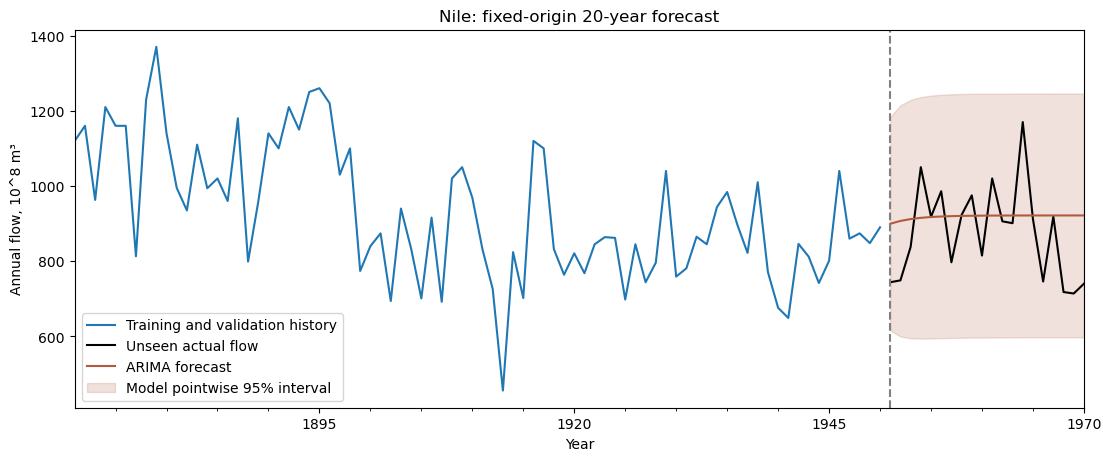

In [3]:
fig, ax = plt.subplots(figsize=(11,4.5),layout='constrained')
history.plot(ax=ax,label='Training and validation history')
test.plot(ax=ax,label='Unseen actual flow',color='black')
prediction.plot(ax=ax,label='ARIMA forecast',color='#b05b3e')
ax.fill_between(test.index,interval.iloc[:,0],interval.iloc[:,1],color='#b05b3e',alpha=0.18,label='Model pointwise 95% interval')
ax.axvline(test.index[0],linestyle='--',color='grey')
ax.set(title='Nile: fixed-origin 20-year forecast',ylabel='Annual flow, 10^8 m³',xlabel='Year')
ax.legend()
fig.savefig('nile-arima.png',dpi=150)
plt.show()

## Interpretation

Orders are selected on ten validation years, then refitted on the first
eighty observations. The last twenty years are used once for comparison.
A low AIC is not held-out accuracy, and a failed ADF rejection does not
prove non-stationarity. The apparent historical level change limits a
single stationary model. The published metric table, including simple
baselines, determines whether the fitted ARIMA improves this test window.
Forecast intervals assume the model is adequate and are pointwise; coverage
on twenty dependent observations does not establish future calibration.